# DS-A2 | Inference and Uncertainty Notebook
## Age-related differences in Black-tailed Godwit migration timing

### Research question
What is the difference in mean timing of southward crossing of
52°N between tracked juvenile and adult Black-tailed Godwits, and how
uncertain is this estimate?

### Data and scope
This analysis continues DS-A1 using the Dryad dataset associated with
Verhoeven et al., “Age-dependent timing and routes demonstrate
developmental plasticity in a long-distance migratory bird”
(DOI: 10.5061/dryad.02v6wwq4j; CC0).

The analysis is restricted to southward crossings of 52°N in 2016–2017.
The outcome is the numerical day-of-year recorded in the Date column.

### Estimand
The juvenile-minus-adult difference in record-weighted mean crossing
date, expressed in days. Each migration record receives equal weight.
Repeated records from the same bird are retained, but dependence is
accounted for by resampling whole birds in the bootstrap.

### Hypotheses
H0: There is no difference in mean crossing date between two age groups.
H1: The mean crossing date is different.

A two-sided 95% cluster-bootstrap confidence interval will quantify
uncertainty in the observed difference.

### Minimum meaningful effect
A difference of 7 days is selected as an interpretable educational
planning threshold. It is not a validated ecological cutoff.
Statistical significance and practical importance will be distinguished.

### Analysis status
The data and general age-group pattern were already inspected in DS-A1.
This protocol is specified before the new A2 calculations, but the
analysis is retrospective and is not presented as preregistered.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Settings for the subsequent analyses
ALPHA = 0.05
MME = 7.0
B = 10_000          # Bootstrap replicates
R = 3_000          # Simulated studies per power scenario

SEEDS = {
    "bootstrap": 20261014,
    "sampling": 20261015,
    "power": 20261016,
    "counterexample": 20261017,
}

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

# Accept either filename
candidates = [
    Path("2.Adult_and_juvenile_timing_forR.csv"),
    Path("2.Adult_and_juvenile_timing_forR(1).csv"),
]
existing = [p for p in candidates if p.is_file()]

if not existing:
    raise FileNotFoundError("Upload the timing CSV through the Files panel.")

file_path = existing[0]

# Freeze the exact input file
expected_hash = (
    "ef3b0967eac749481aaf7f9220ae617ff"
    "70daed3d8f63296dc326ca34947df59"
)
data_hash = hashlib.sha256(file_path.read_bytes()).hexdigest()
assert data_hash == expected_hash, "The input file differs from the audited CSV."

df = pd.read_csv(file_path)

analysis_df = df.loc[
    (df["What 2"] == "Southward Migration")
    & (df["Latitude"] == 52)
    & (df["To Breed"].isin([2016, 2017]))
].copy()

# Checks needed for the inference
required = ["Individual", "Age", "Date", "To Breed"]
assert not analysis_df[required].isna().any().any()
assert analysis_df["Date"].between(1, 366).all()
assert not analysis_df.duplicated(["Individual", "To Breed"]).any()
assert analysis_df.groupby("Individual")["Age"].nunique().eq(1).all()

analysis_df = analysis_df.sort_values(
    ["Age", "Individual", "To Breed"]
).reset_index(drop=True)

summary = analysis_df.groupby("Age").agg(
    records=("Date", "size"),
    birds=("Individual", "nunique"),
    mean_date=("Date", "mean"),
    sd_date=("Date", "std"),
)

analysis_df.to_csv(OUT / "analysis_subset.csv", index=False)

print("SHA-256:", data_hash)
print("\nAnalytical sample:")
print(summary.round(3))
print("\nTotal records:", len(analysis_df))
print("Unique birds:", analysis_df["Individual"].nunique())

SHA-256: ef3b0967eac749481aaf7f9220ae617ff70daed3d8f63296dc326ca34947df59

Analytical sample:
     records  birds  mean_date  sd_date
Age                                    
Ad        50     43    176.960   10.496
Juv       28     28    225.321   13.036

Total records: 78
Unique birds: 71


## Cluster bootstrap: method and assumptions

The analytical subset contains 78 migration records from 71 birds:
28 juvenile records from 28 birds and 50 adult records from 43 birds.
Seven adult birds have records from both years. These records are not
independent observations of different birds.

To account for this dependence, birds are resampled with replacement
separately within each age group. Every selected bird contributes all
its migration records. If a bird is selected more than once, its complete
record set is included the corresponding number of times.

For each bootstrap replicate, the mean crossing date is calculated
across all resampled migration records in each group. The statistic is:

difference = juvenile mean date − adult mean date.

This preserves the record-weighted estimand defined above. It does not
replace it with an equally weighted average of individual-bird means.

The procedure is repeated 10,000 times. The 2.5th and 97.5th percentiles
of the bootstrap estimates form an approximate 95% confidence interval.
Their standard deviation estimates the standard error of the difference.

The method assumes that different birds are approximately independent
and that the observed bird histories adequately represent the
available-record process within each age group. Years are pooled:
the interval is conditional on this two-year window and does not
quantify uncertainty across future years.

The bootstrap addresses sampling variability. It does not correct
selection bias or systematic differences between tracking methods.

Observed difference: 48.36 days
95% cluster-bootstrap CI: [42.72, 54.08] days
Bootstrap standard error: 2.89 days


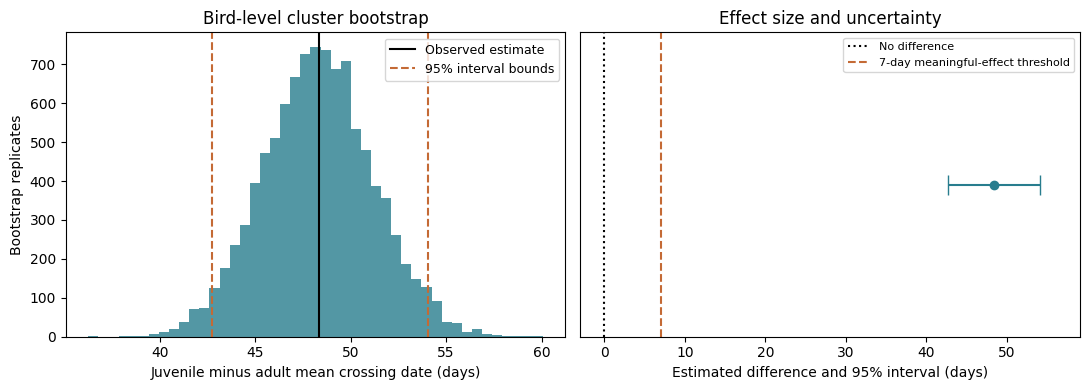

In [2]:
def cluster_bootstrap(data, repeats, seed):
    rng = np.random.default_rng(seed)
    bootstrap_means = {}

    for age in ["Ad", "Juv"]:
        # Each row here represents one bird:
        # sum of its dates and number of its migration records
        clusters = (
            data.loc[data["Age"] == age]
            .groupby("Individual")["Date"]
            .agg(["sum", "count"])
        )

        sums = clusters["sum"].to_numpy()
        counts = clusters["count"].to_numpy()
        n_birds = len(clusters)

        # Resample whole birds, with replacement
        indices = rng.integers(
            0, n_birds,
            size=(repeats, n_birds)
        )

        # Record-weighted mean in each bootstrap sample
        bootstrap_means[age] = (
            sums[indices].sum(axis=1)
            / counts[indices].sum(axis=1)
        )

    return bootstrap_means["Juv"] - bootstrap_means["Ad"]


# Observed difference in record-weighted means
group_means = analysis_df.groupby("Age")["Date"].mean()
delta = float(group_means["Juv"] - group_means["Ad"])

# Bootstrap estimates
boot = cluster_bootstrap(
    analysis_df,
    repeats=B,
    seed=SEEDS["bootstrap"]
)

ci = np.quantile(boot, [ALPHA / 2, 1 - ALPHA / 2])
boot_se = float(boot.std(ddof=1))

print(f"Observed difference: {delta:.2f} days")
print(f"95% cluster-bootstrap CI: [{ci[0]:.2f}, {ci[1]:.2f}] days")
print(f"Bootstrap standard error: {boot_se:.2f} days")

# Save numerical results
pd.DataFrame({
    "replicate": np.arange(B),
    "effect_days": boot
}).to_csv(OUT / "cluster_bootstrap_raw.csv", index=False)

pd.DataFrame([{
    "effect_days": delta,
    "ci_low": ci[0],
    "ci_high": ci[1],
    "bootstrap_se": boot_se,
    "replicates": B
}]).to_csv(OUT / "effect_interval.csv", index=False)

# Plot bootstrap distribution and effect interval
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(
    boot, bins=45,
    color="#287D8E", alpha=0.8
)
axes[0].axvline(
    delta, color="black",
    label="Observed estimate"
)
axes[0].axvline(
    ci[0], color="#C46A35", linestyle="--",
    label="95% interval bounds"
)
axes[0].axvline(
    ci[1], color="#C46A35", linestyle="--"
)
axes[0].set(
    xlabel="Juvenile minus adult mean crossing date (days)",
    ylabel="Bootstrap replicates",
    title="Bird-level cluster bootstrap"
)
axes[0].legend(fontsize=9)

axes[1].errorbar(
    delta, 0,
    xerr=[[delta - ci[0]], [ci[1] - delta]],
    fmt="o", color="#287D8E",
    capsize=7
)
axes[1].axvline(
    0, color="black", linestyle=":",
    label="No difference"
)
axes[1].axvline(
    MME, color="#C46A35", linestyle="--",
    label="7-day meaningful-effect threshold"
)
axes[1].set(
    xlabel="Estimated difference and 95% interval (days)",
    yticks=[],
    xlim=(-3, ci[1] + 5),
    ylim=(-1, 1),
    title="Effect size and uncertainty"
)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(
    OUT / "bootstrap_and_interval.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

## Interpretation of the effect estimate

Juvenile migration records had a mean crossing date 48.36 days later
than adult records. The approximate 95% individual-cluster bootstrap
interval was 42.72–54.08 days, with a bootstrap standard error of
2.89 days.

The interval excludes zero and lies entirely above the selected
seven-day threshold. Under the stated assumptions, the recorded
age-group contrast is therefore distinguishable from zero and exceeds
the educational threshold for practical importance.

This interval quantifies sampling uncertainty in the recorded contrast.
It does not establish the biological cause of the difference or remove
selection and measurement bias. It should not be interpreted as a
95% probability that the fixed true difference lies within these bounds.

## Hypothesis test on the observed data

The null hypothesis of zero juvenile-minus-adult mean difference is
tested directly using the observed 78 migration records.

The record-weighted mean difference is evaluated using a
cluster-robust standard error (CR1), with individual bird as the cluster.
This accounts for dependence between repeated records from the same
bird while retaining the original estimand.

A finite-sample covariance correction is applied. The two-sided
p-value uses a t-distribution with 70 degrees of freedom, corresponding
to 71 individual clusters minus one.

This is an approximate test requiring independence between birds.
It does not correct selection bias, measurement bias or pooled-year
differences.

In [5]:
# Real-data test: no artificial observations are generated here
work = analysis_df.copy()

means = work.groupby("Age")["Date"].mean()
counts = work.groupby("Age").size()

observed_difference = float(means["Juv"] - means["Ad"])

# Residuals from the two observed group means
work["residual"] = (
    work["Date"] - work["Age"].map(means)
)

# Sum residuals within each bird, retaining within-bird dependence
cluster_scores = (
    work.groupby(["Age", "Individual"])["residual"].sum()
)

N = len(work)
G = work["Individual"].nunique()

# Uncorrected cluster variance of the mean difference
variance = sum(
    np.sum(cluster_scores.loc[age].to_numpy() ** 2)
    / counts[age] ** 2
    for age in ["Ad", "Juv"]
)

# CR1 correction for a two-parameter model:
# intercept and juvenile-group indicator
correction = (G / (G - 1)) * ((N - 1) / (N - 2))
cluster_se = np.sqrt(correction * variance)

test_df = G - 1
t_statistic = observed_difference / cluster_se
p_value = 2 * stats.t.sf(abs(t_statistic), df=test_df)

print(f"Observed difference: {observed_difference:.2f} days")
print(f"Cluster-robust standard error: {cluster_se:.2f} days")
print(f"t({test_df}) = {t_statistic:.2f}")
print(f"Two-sided p-value: {p_value:.3e}")

pd.DataFrame([{
    "effect_days": observed_difference,
    "cluster_robust_se": cluster_se,
    "t_statistic": t_statistic,
    "degrees_of_freedom": test_df,
    "p_value": p_value
}]).to_csv(OUT / "observed_data_test.csv", index=False)

Observed difference: 48.36 days
Cluster-robust standard error: 2.92 days
t(70) = 16.56
Two-sided p-value: 6.466e-26


The observed mean difference was 48.36 days. The cluster-robust
standard error was 2.92 days, giving t(70) = 16.56 and a two-sided
p-value of approximately 6.47 × 10⁻²⁶.

Under the stated assumptions, the null hypothesis of zero difference
is rejected. This result agrees with the cluster-bootstrap interval,
which also excludes zero.

The evidence concerns the pooled measured contrast in the available
2016–2017 records. It does not establish a causal effect of age or
guarantee generalisation beyond the selected tracking sample.

## Sampling distribution under a known simulation model

A sampling distribution describes how a statistic varies across repeated
samples generated by the same process.

To demonstrate this explicitly, 3,000 independent two-group samples are
simulated. The true juvenile-minus-adult mean difference is set to
7 days, the selected meaningful-effect threshold.

Each simulated sample contains 28 juvenile birds and 43 adult birds.
Each bird contributes one crossing date. Within each age group,
dates are generated from a normal distribution.

The standard deviations are calibrated using the observed data.
For this calibration, repeated dates from the same adult bird are
averaged first, producing one value per bird. These individual averages
are used only to obtain approximate planning parameters; the primary
record-weighted analysis above is unchanged.

For each simulated sample, the difference between the two sample means
is calculated. The resulting distribution illustrates sampling
variability around a known true effect.

Under this independent normal model, the theoretical standard error is:

SE = sqrt(SD_juvenile² / n_juvenile + SD_adult² / n_adult).

The simulated distribution is compared with this theoretical prediction.
Normality and independence are assumptions of this simulation, not
established properties of the original tracking data. This model also
does not reproduce the original repeated-record design.

Simulated samples: 3000
Birds per sample: 28 juveniles, 43 adults
True difference: 7.00 days
Mean estimated difference: 7.06 days
Empirical standard error: 2.95 days
Theoretical standard error: 2.93 days


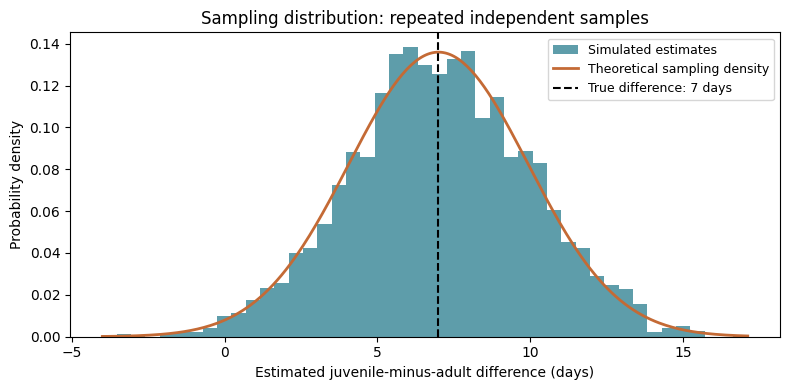

In [3]:
# Obtain one average crossing date per observed bird.
# These values calibrate the simulation SDs only.
bird = (
    analysis_df
    .groupby(["Age", "Individual"], as_index=False)["Date"]
    .mean()
)

j = bird.loc[bird["Age"] == "Juv", "Date"].to_numpy()
ad = bird.loc[bird["Age"] == "Ad", "Date"].to_numpy()

sd_j = float(j.std(ddof=1))
sd_ad = float(ad.std(ddof=1))
mu_ad = float(ad.mean())

n_j = len(j)
n_ad = len(ad)

# Generate new independent samples with a known 7-day effect
rng = np.random.default_rng(SEEDS["sampling"])

sim_j = rng.normal(
    loc=mu_ad + MME,
    scale=sd_j,
    size=(R, n_j)
)

sim_ad = rng.normal(
    loc=mu_ad,
    scale=sd_ad,
    size=(R, n_ad)
)

sim_delta = sim_j.mean(axis=1) - sim_ad.mean(axis=1)

theory_se = np.sqrt(
    sd_j**2 / n_j + sd_ad**2 / n_ad
)
empirical_se = sim_delta.std(ddof=1)

print(f"Simulated samples: {R}")
print(f"Birds per sample: {n_j} juveniles, {n_ad} adults")
print(f"True difference: {MME:.2f} days")
print(f"Mean estimated difference: {sim_delta.mean():.2f} days")
print(f"Empirical standard error: {empirical_se:.2f} days")
print(f"Theoretical standard error: {theory_se:.2f} days")

# Save all simulated estimates and the comparison with theory
pd.DataFrame({
    "replicate": np.arange(R),
    "estimated_difference": sim_delta
}).to_csv(
    OUT / "sampling_distribution_raw.csv",
    index=False
)

pd.DataFrame([{
    "true_difference": MME,
    "mean_estimated_difference": sim_delta.mean(),
    "empirical_se": empirical_se,
    "theoretical_se": theory_se,
    "n_juvenile": n_j,
    "n_adult": n_ad,
    "sd_juvenile": sd_j,
    "sd_adult": sd_ad
}]).to_csv(
    OUT / "sampling_distribution_summary.csv",
    index=False
)

# Plot the sampling distribution
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    sim_delta,
    bins=45,
    density=True,
    color="#287D8E",
    alpha=0.75,
    label="Simulated estimates"
)

xx = np.linspace(
    sim_delta.min(),
    sim_delta.max(),
    300
)

ax.plot(
    xx,
    stats.norm.pdf(xx, loc=MME, scale=theory_se),
    color="#C46A35",
    linewidth=2,
    label="Theoretical sampling density"
)

ax.axvline(
    MME,
    color="black",
    linestyle="--",
    label="True difference: 7 days"
)

ax.set(
    xlabel="Estimated juvenile-minus-adult difference (days)",
    ylabel="Probability density",
    title="Sampling distribution: repeated independent samples"
)

ax.legend(fontsize=9)
plt.tight_layout()

plt.savefig(
    OUT / "sampling_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### Interpretation

Although every simulated study has the same true difference of 7 days,
the estimated differences vary because each study contains a different
random sample.

The mean estimate across 3,000 simulations was approximately 7.06 days,
close to the known true value. The empirical standard error was
approximately 2.95 days, closely matching the theoretical value of
2.93 days.

This agreement supports the implementation of the sampling-distribution
simulation under its specified assumptions. It does not validate those
assumptions for the real tracking data.

The histogram represents variation in estimated differences between
sample means, rather than variation in individual migration dates.

## Power analysis

Power is the probability that a statistical test rejects the null
hypothesis when a specified nonzero effect exists.

For each scenario, 3,000 independent studies are simulated. Each bird
contributes one crossing date. A two-sided Welch t-test compares
juvenile and adult mean dates, using a significance level of 0.05.
Welch's test does not require equal group variances.

Three factors are varied:
- Sample size: 10, 20, 40 or 80 independent birds per age group.
- Noise: 0.5, 1 or 2 times the calibrated group standard deviations.
- True difference: 0, 3.5, 7 or 14 days.

For nonzero differences, power is estimated as the proportion of
studies with p < 0.05. For a zero difference, this proportion estimates
the false-positive rate instead.

These are prospective planning scenarios under an independent normal
model, not estimates of the power of the original clustered study.

Monte Carlo standard errors and 95% Wilson intervals quantify
uncertainty due to the finite number of simulated studies.

Power for a 7-day effect at baseline noise:
 n_per_group  rate  mc_low  mc_high
          10 0.227   0.213    0.243
          20 0.433   0.415    0.451
          40 0.743   0.727    0.759
          80 0.958   0.950    0.964

False-positive rates when the true difference is zero:
 noise  n_per_group  rate  mc_low  mc_high
   0.5           10 0.049   0.042    0.058
   0.5           20 0.050   0.042    0.058
   0.5           40 0.052   0.045    0.061
   0.5           80 0.053   0.045    0.061
   1.0           10 0.054   0.046    0.062
   1.0           20 0.056   0.049    0.065
   1.0           40 0.052   0.044    0.060
   1.0           80 0.055   0.047    0.064
   2.0           10 0.044   0.038    0.052
   2.0           20 0.057   0.049    0.066
   2.0           40 0.053   0.046    0.062
   2.0           80 0.053   0.046    0.062


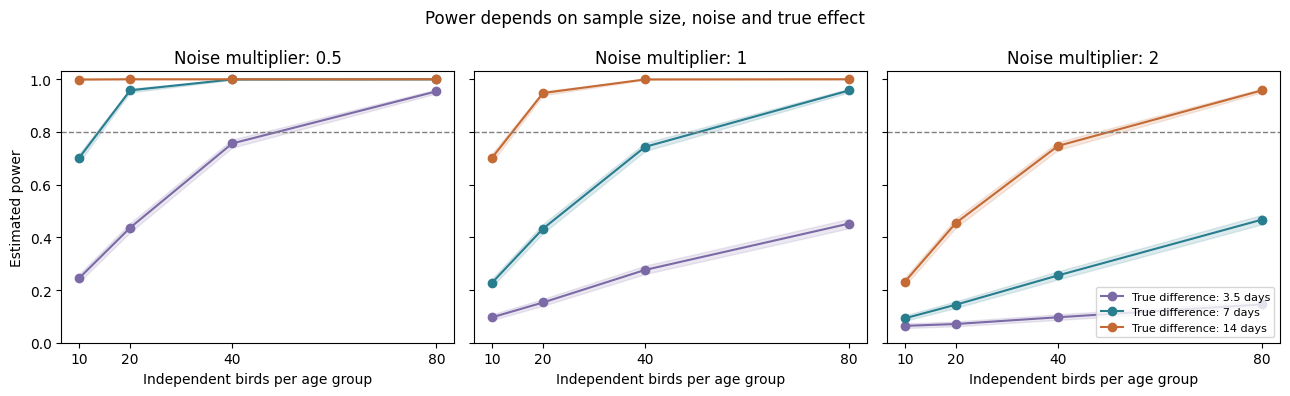

In [4]:
# Summarise how often the test rejects H0
def rejection_summary(pvalues):
    total = len(pvalues)
    hits = int(np.count_nonzero(pvalues < ALPHA))
    rate = hits / total

    # Monte Carlo standard error
    mcse = np.sqrt(rate * (1 - rate) / total)

    # Wilson 95% interval for the rejection probability
    z = stats.norm.ppf(0.975)
    denominator = 1 + z**2 / total

    centre = (
        rate + z**2 / (2 * total)
    ) / denominator

    half_width = (
        z * np.sqrt(
            rate * (1 - rate) / total
            + z**2 / (4 * total**2)
        ) / denominator
    )

    return {
        "rejections": hits,
        "rate": rate,
        "mcse": mcse,
        "mc_low": centre - half_width,
        "mc_high": centre + half_width,
    }


rng = np.random.default_rng(SEEDS["power"])

rows = []
raw_pvalues = {}

for noise in [0.5, 1.0, 2.0]:
    for n in [10, 20, 40, 80]:
        for effect in [0.0, 3.5, 7.0, 14.0]:

            # Each row is one simulated study
            juvenile = rng.normal(
                loc=mu_ad + effect,
                scale=noise * sd_j,
                size=(R, n)
            )

            adult = rng.normal(
                loc=mu_ad,
                scale=noise * sd_ad,
                size=(R, n)
            )

            # One Welch test per simulated study
            pvalues = stats.ttest_ind(
                juvenile,
                adult,
                axis=1,
                equal_var=False,
                alternative="two-sided"
            ).pvalue

            rows.append({
                "noise": noise,
                "n_per_group": n,
                "effect": effect,
                "replicates": R,
                **rejection_summary(pvalues)
            })

            key = f"noise{noise}_n{n}_effect{effect}"
            raw_pvalues[key] = pvalues

power = pd.DataFrame(rows)

# Save all scenarios and all simulated p-values
power.to_csv(OUT / "power_results.csv", index=False)

np.savez_compressed(
    OUT / "power_raw_pvalues.npz",
    **raw_pvalues
)

print("Power for a 7-day effect at baseline noise:")
print(
    power.loc[
        (power["noise"] == 1.0)
        & (power["effect"] == 7.0),
        ["n_per_group", "rate", "mc_low", "mc_high"]
    ].round(3).to_string(index=False)
)

print("\nFalse-positive rates when the true difference is zero:")
print(
    power.loc[
        power["effect"] == 0,
        ["noise", "n_per_group", "rate", "mc_low", "mc_high"]
    ].round(3).to_string(index=False)
)

# Plot power against sample size
fig, axes = plt.subplots(
    1, 3, figsize=(13, 4), sharey=True
)

for ax, noise in zip(axes, [0.5, 1.0, 2.0]):
    for effect, color in [
        (3.5, "#7C6AA6"),
        (7.0, "#287D8E"),
        (14.0, "#C46A35"),
    ]:
        q = power.loc[
            (power["noise"] == noise)
            & (power["effect"] == effect)
        ].sort_values("n_per_group")

        ax.plot(
            q["n_per_group"],
            q["rate"],
            "o-",
            color=color,
            label=f"True difference: {effect:g} days"
        )

        ax.fill_between(
            q["n_per_group"].to_numpy(),
            q["mc_low"].to_numpy(),
            q["mc_high"].to_numpy(),
            color=color,
            alpha=0.15
        )

    ax.axhline(
        0.8, color="grey",
        linestyle="--", linewidth=1
    )

    ax.set(
        xlabel="Independent birds per age group",
        title=f"Noise multiplier: {noise:g}",
        xticks=[10, 20, 40, 80],
        ylim=(0, 1.03)
    )

axes[0].set_ylabel("Estimated power")
axes[-1].legend(fontsize=8, loc="lower right")

fig.suptitle(
    "Power depends on sample size, noise and true effect"
)

plt.tight_layout()
plt.savefig(
    OUT / "power.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### Interpretation of the power analysis

Power increased with sample size and true effect size and decreased
as the within-group noise increased.

For a seven-day effect at baseline noise, estimated power was 22.7%,
43.3%, 74.3% and 95.8% with 10, 20, 40 and 80 birds per group,
respectively. Thus, a real effect can remain undetected in a small
sample; a nonsignificant result does not establish absence of a
meaningful difference.

Across the zero-effect scenarios, false-positive rates ranged from
approximately 4.4% to 5.7%. Their Monte Carlo intervals included the
nominal 5% level, supporting null calibration under the simulated model.

The shaded bands represent Monte Carlo uncertainty in estimated power,
not confidence intervals for the migration-timing difference.

These results depend on the assumed normal distributions, calibrated
standard deviations and independence of birds. They are conditional
planning calculations and do not establish a definitive fieldwork
sample-size requirement.

## Assumption-violating counterexample: dependent observations

Welch's test assumes independent observations. To demonstrate the
consequences of violating this assumption, 3,000 studies are simulated
with 20 independent birds per age group and a true mean difference
of zero.

Each study is analysed in two ways:

1. A valid Welch test using one observation per independent bird.
2. A naive Welch test after copying each observation five times and
   incorrectly treating the copies as independent observations.

The copies add no new birds or information. Nevertheless, the naive
test treats each group as containing 100 independent observations
instead of 20.

Because the true difference is zero, the rejection proportion estimates
the false-positive rate. A correctly calibrated test should reject
approximately 5% of the time.

Exact copying creates perfect within-bird dependence. This is a labelled
synthetic stress test, not an estimate of the dependence or error
inflation in the original dataset. The source data are not modified.

                       method  actual_birds_per_group  rows_per_group  rate
            Independent birds                      20              20 0.047
Copies treated as independent                      20             100 0.376


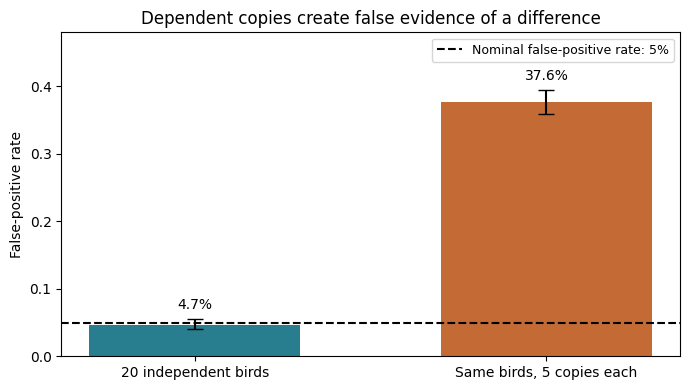

In [6]:
rng = np.random.default_rng(SEEDS["counterexample"])

n_birds = 20
copies = 5

# No true group difference: both population means are zero
null_j = rng.normal(
    loc=0,
    scale=sd_j,
    size=(R, n_birds)
)

null_ad = rng.normal(
    loc=0,
    scale=sd_ad,
    size=(R, n_birds)
)

# Correct analysis: one observation per independent bird
p_valid = stats.ttest_ind(
    null_j,
    null_ad,
    axis=1,
    equal_var=False
).pvalue

# Incorrect analysis: copies are treated as independent birds
copied_j = np.repeat(null_j, copies, axis=1)
copied_ad = np.repeat(null_ad, copies, axis=1)

p_naive = stats.ttest_ind(
    copied_j,
    copied_ad,
    axis=1,
    equal_var=False
).pvalue

counterexample = pd.DataFrame([
    {
        "method": "Independent birds",
        "actual_birds_per_group": n_birds,
        "rows_per_group": n_birds,
        **rejection_summary(p_valid)
    },
    {
        "method": "Copies treated as independent",
        "actual_birds_per_group": n_birds,
        "rows_per_group": n_birds * copies,
        **rejection_summary(p_naive)
    }
])

print(counterexample[
    ["method", "actual_birds_per_group", "rows_per_group", "rate"]
].round(3).to_string(index=False))

# Retain results and original simulated observations
counterexample.to_csv(
    OUT / "counterexample_results.csv",
    index=False
)

np.savez_compressed(
    OUT / "counterexample_raw.npz",
    juvenile_original=null_j,
    adult_original=null_ad,
    valid_pvalues=p_valid,
    naive_pvalues=p_naive
)

# Plot false-positive rates with Monte Carlo intervals
rates = counterexample["rate"].to_numpy()
lower = counterexample["mc_low"].to_numpy()
upper = counterexample["mc_high"].to_numpy()

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    [0, 1],
    rates,
    color=["#287D8E", "#C46A35"],
    width=0.6
)

ax.errorbar(
    [0, 1],
    rates,
    yerr=[rates - lower, upper - rates],
    fmt="none",
    color="black",
    capsize=6
)

ax.axhline(
    ALPHA,
    color="black",
    linestyle="--",
    label="Nominal false-positive rate: 5%"
)

for position, rate in enumerate(rates):
    ax.text(
        position,
        upper[position] + 0.015,
        f"{rate:.1%}",
        ha="center"
    )

ax.set(
    xticks=[0, 1],
    xticklabels=[
        "20 independent birds",
        "Same birds, 5 copies each"
    ],
    ylabel="False-positive rate",
    ylim=(0, 0.48),
    title="Dependent copies create false evidence of a difference"
)

ax.legend(fontsize=9)
plt.tight_layout()

plt.savefig(
    OUT / "counterexample.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### Counterexample interpretation

With independent birds, the false-positive rate was approximately
4.7%, close to the nominal 5% significance level.

After each observation was copied five times and the copies were
treated as independent, the false-positive rate increased to
approximately 37.6%. No additional birds or independent information
had been introduced.

The changed conclusion is consequential: under a zero true effect,
the naive analysis frequently produces apparently significant
evidence of a group difference.

This demonstrates that increasing the number of rows does not
necessarily increase the amount of independent information.
The consequences depend on the degree and structure of dependence;
the simulated inflation should not be attributed directly to the
original dataset.

In the real-data analysis, repeated observations were handled by
resampling whole birds for the bootstrap and clustering the standard
error by bird for the hypothesis test.

## Verification

The calculations are checked by:
- reproducing the observed difference directly from group means;
- comparing a manually calculated Welch statistic and p-value with SciPy;
- verifying reproducibility of the cluster bootstrap with the same seed;
- comparing the simulated sampling standard error with its theoretical value.

These numerical checks assess implementation. They do not establish
representativeness of the sample or eliminate measurement bias.

In [7]:
# 1. Verify the observed difference directly
direct_difference = (
    analysis_df.loc[analysis_df["Age"] == "Juv", "Date"].mean()
    - analysis_df.loc[analysis_df["Age"] == "Ad", "Date"].mean()
)

assert np.isclose(delta, direct_difference)
assert np.isclose(observed_difference, direct_difference)
print("Observed difference check: PASS")

# 2. Independently calculate Welch's test for one simulated study
x = sim_j[0]
y = sim_ad[0]

vx = x.var(ddof=1) / len(x)
vy = y.var(ddof=1) / len(y)

manual_t = (x.mean() - y.mean()) / np.sqrt(vx + vy)

manual_df = (
    (vx + vy)**2
    / (vx**2 / (len(x) - 1) + vy**2 / (len(y) - 1))
)

manual_p = 2 * stats.t.sf(abs(manual_t), df=manual_df)
scipy_result = stats.ttest_ind(x, y, equal_var=False)

assert np.isclose(manual_t, scipy_result.statistic)
assert np.isclose(manual_p, scipy_result.pvalue)
print("Manual Welch calculation versus SciPy: PASS")

# 3. Verify fixed-seed bootstrap reproducibility
boot_check = cluster_bootstrap(
    analysis_df, B, SEEDS["bootstrap"]
)

assert np.array_equal(boot, boot_check)
print("Fixed-seed bootstrap reproducibility: PASS")

# 4. Report agreement with the known simulation model
print(
    f"Sampling SE: simulated = {sim_delta.std(ddof=1):.3f}, "
    f"theoretical = {theory_se:.3f}"
)

Observed difference check: PASS
Manual Welch calculation versus SciPy: PASS
Fixed-seed bootstrap reproducibility: PASS
Sampling SE: simulated = 2.955, theoretical = 2.934


## Conclusions and limitations

In the available 2016–2017 records, juvenile Black-tailed Godwits
crossed 52°N during southward migration an average of 48.36 days later
than adults. The 95% individual-cluster bootstrap interval was
42.72–54.08 days.

The observed-data cluster-robust test also provided strong evidence
against a zero mean difference: t(70) = 16.56, p ≈ 6.47 × 10⁻²⁶.
Both methods account for repeated records within birds and support
the same conclusion about the pooled measured contrast.

The simulations demonstrated sampling variability and showed that
power increases with sample size and effect size and decreases with
noise. The dependence counterexample showed that treating copied
observations as independent can severely inflate false-positive rates.

### Limitations

1. Selection: birds with usable tracking records are a selected subset
   of tagged birds. Mortality, recapture and device retrieval can affect
   inclusion. Bootstrap resampling cannot correct this selection.

2. Measurement: juvenile and adult timing was obtained using different
   tracking systems. The analysis does not propagate individual-date
   reconstruction uncertainty or correct device-specific bias.

3. Years: 2016 and 2017 were pooled with unequal age-group sample sizes.
   The effect is a pooled contrast, not a year-adjusted age coefficient.
   The interval does not quantify variability across future years.

4. Assumptions: the observed-data methods assume independence between
   birds. The prospective power calculations additionally assume normal
   distributions and one observation per independent bird.

5. Threshold: seven days was an educational meaningful-effect threshold,
   not a validated ecological cutoff.

### Claim boundary

The results establish a difference in recorded timing within the
analysed sample under the stated assumptions. They do not establish
its biological cause, a causal effect of age, or universal applicability
to other populations and years.

### Reflection

A small p-value and a narrow interval do not guarantee unbiased or
representative evidence. More records improve inference only when
their information content and dependence are handled appropriately.

## References

- Verhoeven, M. A. et al. (2022). Age-dependent timing and routes
  demonstrate developmental plasticity in a long-distance migratory bird
  [Dataset]. Dryad. https://doi.org/10.5061/dryad.02v6wwq4j.
  Published dataset version: 3 December 2021. CC0.

- SciPy documentation: Welch's test.
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

- Statsmodels documentation and implementation: cluster-robust
  inference and CR1 covariance correction.
  https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html
  https://www.statsmodels.org/stable/_modules/statsmodels/stats/sandwich_covariance.html

## AI-use disclosure

ChatGPT assisted with Python codes.

Accepted recommendations included resampling complete bird histories,
distinguishing real-data inference from prospective power simulations,
and documenting the retrospective status of the analysis.

Independent-row inference was rejected as the primary real-data method
because some birds contributed repeated records. It was used only in
the explicitly labelled counterexample.

The verification code was also AI-assisted.

In [8]:
import json
import platform
import scipy
import matplotlib

environment = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
}

settings = {
    "input_sha256": data_hash,
    "alpha": ALPHA,
    "meaningful_effect_days": MME,
    "bootstrap_replicates": B,
    "simulation_replicates": R,
    "seeds": SEEDS,
    "environment": environment,
    "analysis_status": "Retrospective continuation of DS-A1",
}

(OUT / "settings.json").write_text(
    json.dumps(settings, indent=2),
    encoding="utf-8"
)

requirements = "\n".join(
    f"{package}=={environment[package]}"
    for package in ["numpy", "pandas", "scipy", "matplotlib"]
)

(OUT / "requirements.txt").write_text(
    requirements + "\n",
    encoding="utf-8"
)

print("Environment:", environment)
print("Settings and dependency versions saved.")

Environment: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'matplotlib': '3.10.0'}
Settings and dependency versions saved.
